google/deepmind vertical stack
- grain, flax, optax, jax, orbax

In [1]:
# pip install tensorflow-datasets
import grain
import tensorflow_datasets as tfds
ds = tfds.as_numpy(tfds.load("mnist", split="train", batch_size=-1))
x_train = ds["image"].reshape(-1, 784).astype("float32") / 255.0
y_train = ds["label"]

train_ds = (
    grain.MapDataset.range(len(x_train))
    .shuffle(seed=42)
    .map(lambda i: {"x": x_train[i], "y": y_train[i]})
    .batch(128, drop_remainder=True)
)

I0000 00:00:1790666326.967871  650045 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1790666329.144202  650045 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1790666331.171291  650045 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [8]:
from flax import nnx
import optax, jax.numpy as jnp

class MLP(nnx.Module):
    def __init__(self, rngs):
        self.l1 = nnx.Linear(784, 128, rngs=rngs)
        self.l2 = nnx.Linear(128, 10, rngs=rngs)
    def __call__(self, x):
        return self.l2(nnx.relu(self.l1(x)))

model = MLP(nnx.Rngs(0))
model

MLP( # Param: 101,770 (407.1 KB)
  l1=Linear( # Param: 100,480 (401.9 KB)
    kernel=Param( # 100,352 (401.4 KB)
      value=Array(shape=(784, 128), dtype=dtype('float32'))
    ),
    bias=Param( # 128 (512 B)
      value=Array(shape=(128,), dtype=dtype('float32'))
    ),
    in_features=784,
    out_features=128,
    use_bias=True,
    dtype=None,
    param_dtype=float32,
    precision=None,
    dot_general=<function dot_general at 0x7cdb5b32fb00>,
    promote_dtype=<function promote_dtype at 0x7cdad0b8c860>,
    preferred_element_type=None
  ),
  l2=Linear( # Param: 1,290 (5.2 KB)
    kernel=Param( # 1,280 (5.1 KB)
      value=Array(shape=(128, 10), dtype=dtype('float32'))
    ),
    bias=Param( # 10 (40 B)
      value=Array(shape=(10,), dtype=dtype('float32'))
    ),
    in_features=128,
    out_features=10,
    use_bias=True,
    dtype=None,
    param_dtype=float32,
    precision=None,
    dot_general=<function dot_general at 0x7cdb5b32fb00>,
    promote_dtype=<function promote_dty

The PyTorch equivalent would be calling clip_grad_norm_ manually before optimizer.step(). In Optax, that clipping becomes part of the optimizer itself.

In [3]:
tx = optax.chain(
    optax.clip_by_global_norm(1.0),  # 1. clip gradients
    optax.add_decayed_weights(1e-4), # 2. add weight decay
    optax.scale_by_adam(),           # 3. Adam's moment-based rescaling
    optax.scale_by_learning_rate(1e-3),  # 4. multiply by -lr
)
optimizer = nnx.Optimizer(model, tx, wrt=nnx.Param)
optimizer

Optimizer( # OptArray: 1 (4 B), OptVariable: 203,540 (814.2 KB), OptState: 1 (4 B), Total: 203,542 (814.2 KB)
  graph=None,
  step=OptState( # 1 (4 B)
    value=Array(0, dtype=uint32)
  ),
  tx=(<function chain.<locals>.init_fn at 0x7cdacf81f560>, <function chain.<locals>.update_fn at 0x7cdacf81f600>),
  opt_state=((), (), (OptArray( # 1 (4 B)
    value=Array(0, dtype=int32)
  ), State({
    'l1': {
      'bias': OptVariable( # 128 (512 B)
        value=Array(shape=(128,), dtype=dtype('float32'))
      ),
      'kernel': OptVariable( # 100,352 (401.4 KB)
        value=Array(shape=(784, 128), dtype=dtype('float32'))
      )
    },
    'l2': {
      'bias': OptVariable( # 10 (40 B)
        value=Array(shape=(10,), dtype=dtype('float32'))
      ),
      'kernel': OptVariable( # 1,280 (5.1 KB)
        value=Array(shape=(128, 10), dtype=dtype('float32'))
      )
    }
  }), State({
    'l1': {
      'bias': OptVariable( # 128 (512 B)
        value=Array(shape=(128,), dtype=dtype('float32'))

In [4]:
# optimized by kernels
@nnx.jit
def train_step(model, optimizer, x, y):

    def loss_fn(model):
        logits = model(x)
        return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean()

	# call loss_fn, forward pass, get loss, return gradients 
    loss, grads = nnx.value_and_grad(loss_fn)(model)

	# optimizer.step
    optimizer.update(model, grads)

    return loss

In [5]:
import orbax.checkpoint as ocp
mngr = ocp.CheckpointManager(
    "ckpts",
    options=ocp.CheckpointManagerOptions(max_to_keep=3, save_interval_steps=1000),
)

In [9]:

lossi = []
for epoch in range(10):
	for batch in train_ds:
		loss = train_step(model, optimizer, batch["x"], batch["y"])
		lossi.append(loss)
	print(epoch, loss)
	

0 0.13557333
1 0.08610983
2 0.053831957
3 0.03244867
4 0.02201141
5 0.017414842
6 0.014651304
7 0.012991736
8 0.01183667
9 0.011270663


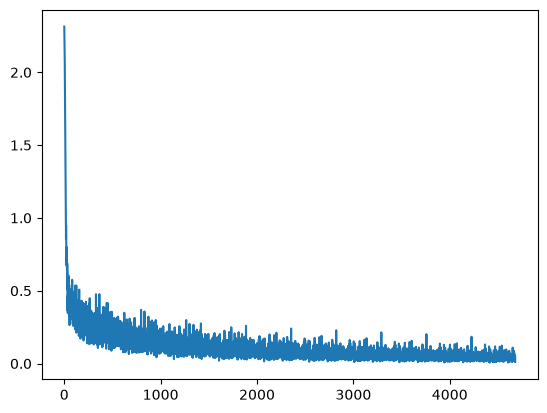

In [10]:
import matplotlib.pyplot as plt
plt.plot(lossi)